# Imports and setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

from churn.config import SEED, TARGET, RAW_PATH, FIG_DIR
from churn.data import load_raw, clean
from churn.features import build_preprocessor

# Data and model

In [2]:
df = clean(load_raw(RAW_PATH))
X, y = df.drop(columns=[TARGET]), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

model = Pipeline([
    ("prep", build_preprocessor()),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Gender','Senior Citizen','Partner',...,'Monthly Charges','Total Charges', 'CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, al

# Logistic regression coefficients

## Coefficients and odds ratios

In [3]:
names = model.named_steps["prep"].get_feature_names_out()
coefs = model.named_steps["clf"].coef_[0]

coef_df = (
    pd.DataFrame({"feature": names, "coef": coefs, "odds_ratio": np.exp(coefs)})
    .sort_values("coef")
)
coef_df.round(3)

,feature,coef,odds_ratio
5,cat__Dependents_Yes,-1.620,0.198
0,num__Tenure Months,-0.824,0.438
33,cat__Contract_Two year,-0.766,0.465
10,cat__Internet Service_DSL,-0.656,0.519
1,num__Monthly Charges,-0.416,0.659
12,cat__Internet Service_No,-0.318,0.728
20,cat__Device Protection_No internet service,-0.318,0.728
14,cat__Online Security_No internet service,-0.318,0.728
26,cat__Streaming TV_No internet service,-0.318,0.728
23,cat__Tech Support_No internet service,-0.318,0.728


## Top 15 coefficients by absolute value

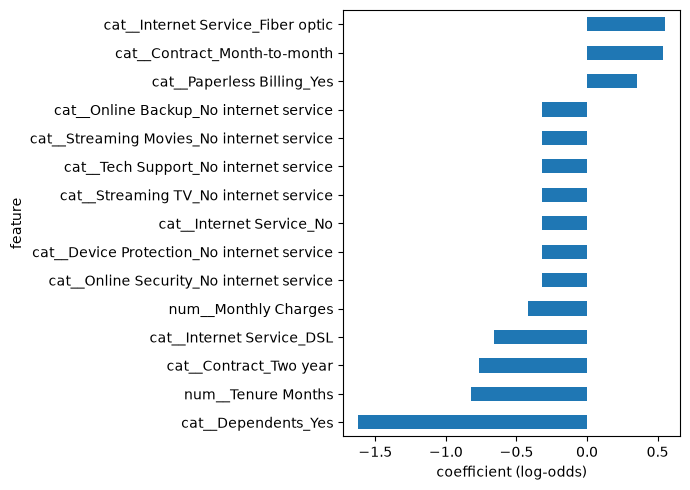

In [4]:
top = coef_df.reindex(coef_df["coef"].abs().sort_values(ascending=False).index).head(15)
top.sort_values("coef").plot.barh(x="feature", y="coef", legend=False, figsize=(7, 5))
plt.xlabel("coefficient (log-odds)")
plt.tight_layout()
plt.show()

# Permutation importance

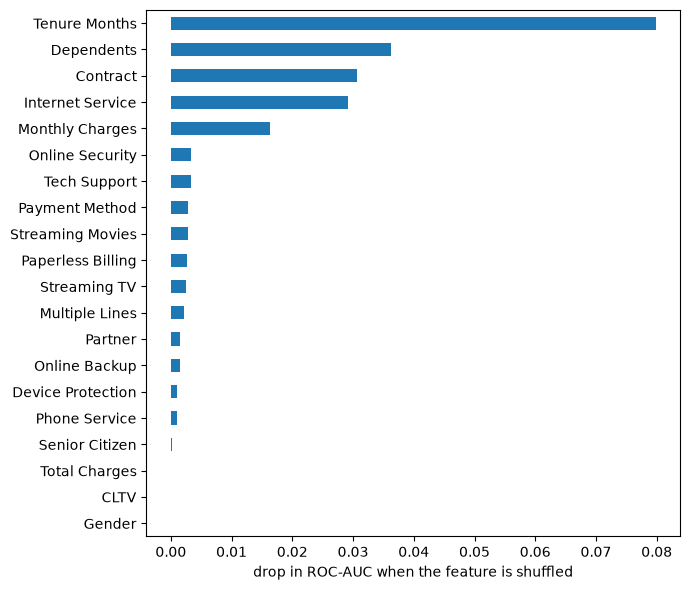

In [5]:
result = permutation_importance(
    model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1
)
imp = pd.Series(result.importances_mean, index=X_test.columns).sort_values()
imp.plot.barh(figsize=(7, 6))
plt.xlabel("drop in ROC-AUC when the feature is shuffled")
plt.tight_layout()
plt.savefig(FIG_DIR / "permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

# Conclusions

- Five features carry almost all the signal (permutation importance, drop in test ROC-AUC): `Tenure Months` (about 0.08), `Dependents` (0.04), `Contract` (0.03), `Internet Service` (0.03), `Monthly Charges` (0.02). The rest add 0.003 or less.
- Coefficients agree on the main drivers: longer tenure, dependents and two-year contracts lower churn risk; month-to-month contracts and fiber optic raise it.
- `Gender` has no effect. `Total Charges` and `CLTV` show zero importance, which confirms they are excluded from the model input.
- Coefficients must be read with care: they are effects given all other features, not causes. `Monthly Charges` has a negative coefficient (while churned customers pay more) because the services priced into it are also in the model.
- The six "No internet service" columns share the same coefficient (-0.318) because they duplicate `Internet Service = No`; merging them into "No" would make the coefficients easier to read.